Download the dataset available at https://bit.ly/3ufnsgF, which contains data on users’ sentiment towards a web platform.
Carry out the following tasks:

In [19]:
import sklearn as skl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import preprocessing

## T1
Load the dataset. Apply methods for data exploration, i.e. analyze the data in relation to the users:
   - Central tendency;
   - Statistical dispersion;
   - Correlation between features


In [20]:
# Load the data
sent_analysis = pd.read_csv("datasets3/sentiment_analysis.csv")

In [21]:
sent_analysis.head()

,CustomerKey,WebActivity,Sentiment Analysis,SentimentRating,MaritalStatus,Gender,EstimatedYearlyIncome,NumberOfContracts,Age,Target,Available401K,CustomerValueSegment,ChurnScore,CallActivity,Products,birthday
0,11000,0,Slightly Negative,2,M,M,90000,0,44,1,1,1,0.1,4,private investment,1972-01-14
1,11000,0,Slightly Negative,2,M,M,90000,0,44,1,1,1,0.1,4,private investment,1971-08-28
2,11001,3,Slightly Positive,3,S,M,60000,1,45,1,0,1,0.0,4,private investment,1970-06-26
3,11001,3,Slightly Positive,3,S,M,60000,1,45,1,0,1,0.0,4,private investment,1971-02-11
4,11002,3,Slightly Positive,3,M,M,60000,1,45,1,1,1,0.2,4,private investment,1971-01-27


In [22]:
sent_analysis.info()

<class 'pandas.DataFrame'>
RangeIndex: 15167 entries, 0 to 15166
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   CustomerKey            15167 non-null  int64  
 1   WebActivity            15167 non-null  int64  
 2   Sentiment Analysis     15167 non-null  str    
 3   SentimentRating        15167 non-null  int64  
 4   MaritalStatus          15167 non-null  str    
 5   Gender                 15167 non-null  str    
 6   EstimatedYearlyIncome  15167 non-null  int64  
 7   NumberOfContracts      15167 non-null  int64  
 8   Age                    15167 non-null  int64  
 9   Target                 15167 non-null  int64  
 10  Available401K          15167 non-null  int64  
 11  CustomerValueSegment   15167 non-null  int64  
 12  ChurnScore             15167 non-null  float64
 13  CallActivity           15167 non-null  int64  
 14  Products               15167 non-null  str    
 15  birthday     

In [31]:
# Remoção de linhas duplicadas
sent_analysis_no_duplicates = sent_analysis.drop_duplicates()
sent_analysis.info()

<class 'pandas.DataFrame'>
Index: 15151 entries, 0 to 15166
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   CustomerKey            15151 non-null  int64  
 1   WebActivity            15151 non-null  int64  
 2   Sentiment Analysis     15151 non-null  str    
 3   SentimentRating        15151 non-null  int64  
 4   MaritalStatus          15151 non-null  str    
 5   Gender                 15151 non-null  str    
 6   EstimatedYearlyIncome  15151 non-null  int64  
 7   NumberOfContracts      15151 non-null  int64  
 8   Age                    15151 non-null  int64  
 9   Target                 15151 non-null  int64  
 10  Available401K          15151 non-null  int64  
 11  CustomerValueSegment   15151 non-null  int64  
 12  ChurnScore             15151 non-null  float64
 13  CallActivity           15151 non-null  int64  
 14  Products               15151 non-null  str    
 15  birthday          

In [33]:
sent_analysis_no_duplicates_and_keys = sent_analysis_no_duplicates.drop('CustomerKey', axis=1)
sent_analysis_no_duplicates_and_keys.describe()

,WebActivity,SentimentRating,EstimatedYearlyIncome,NumberOfContracts,Age,Target,Available401K,CustomerValueSegment,ChurnScore,CallActivity
count,15151.000000,15151.000000,15151.000000,15151.000000,15151.000000,15151.000000,15151.000000,15151.000000,15151.000000,15151.000000
mean,0.999868,1.851693,57716.982377,1.465712,48.208435,0.486833,0.696456,2.097221,0.268979,3.236684
std,1.520292,1.620124,32099.608194,1.145228,11.301274,0.499843,0.459803,0.688989,0.332418,1.262698
min,0.000000,0.000000,10000.000000,0.000000,29.000000,0.000000,0.000000,1.000000,0.000000,1.000000
25%,0.000000,0.000000,30000.000000,1.000000,40.000000,0.000000,0.000000,2.000000,0.000000,2.000000
50%,0.000000,2.000000,60000.000000,1.000000,46.000000,0.000000,1.000000,2.000000,0.100000,3.000000
75%,2.000000,3.000000,70000.000000,2.000000,56.000000,1.000000,1.000000,3.000000,0.500000,4.000000
max,5.000000,5.000000,170000.000000,4.000000,100.000000,1.000000,1.000000,3.000000,1.000000,5.000000


In [35]:
num_cols = [c for c in sent_analysis_no_duplicates_and_keys.select_dtypes(include="number").columns]

central_tendency = pd.DataFrame({
    "mean": sent_analysis_no_duplicates_and_keys[num_cols].mean(),
    "median": sent_analysis_no_duplicates_and_keys[num_cols].median(),
    "mode": sent_analysis_no_duplicates_and_keys[num_cols].mode().iloc[0],
})
central_tendency

,mean,median,mode
WebActivity,0.999868,0.0,0.0
SentimentRating,1.851693,2.0,0.0
EstimatedYearlyIncome,57716.982377,60000.0,60000.0
NumberOfContracts,1.465712,1.0,2.0
Age,48.208435,46.0,41.0
Target,0.486833,0.0,0.0
Available401K,0.696456,1.0,1.0
CustomerValueSegment,2.097221,2.0,2.0
ChurnScore,0.268979,0.1,0.0
CallActivity,3.236684,3.0,4.0


In [37]:
# Moda das features categóricas
cat_cols = sent_analysis_no_duplicates_and_keys.select_dtypes(exclude="number").columns.tolist()
sent_analysis_no_duplicates_and_keys[cat_cols].mode().iloc[0]


Sentiment Analysis         Very Negative
MaritalStatus                          M
Gender                                 M
Products              private investment
birthday                      1975-01-06
Name: 0, dtype: str

In [39]:
statistical_dispersion = pd.DataFrame({
    "min": sent_analysis_no_duplicates_and_keys[num_cols].min(),
    "median": sent_analysis_no_duplicates_and_keys[num_cols].median(),
    "max": sent_analysis_no_duplicates_and_keys[num_cols].max(),
    "range": sent_analysis_no_duplicates_and_keys[num_cols].max() - sent_analysis_no_duplicates_and_keys[num_cols].min(),
    "var": sent_analysis_no_duplicates_and_keys[num_cols].var(),
    "std": sent_analysis_no_duplicates_and_keys[num_cols].std(),
    "IQR": sent_analysis_no_duplicates_and_keys[num_cols].quantile(0.75) - sent_analysis_no_duplicates_and_keys[num_cols].quantile(0.25),
    "skew": sent_analysis_no_duplicates_and_keys[num_cols].skew(),
    "kurtosis": sent_analysis_no_duplicates_and_keys[num_cols].kurt(),
})
statistical_dispersion

,min,median,max,range,var,std,IQR,skew,kurtosis
WebActivity,0.0,0.0,5.0,5.0,2.311287e+00,1.520292,2.0,1.394502,0.685182
SentimentRating,0.0,2.0,5.0,5.0,2.624802e+00,1.620124,3.0,0.481691,-0.958353
EstimatedYearlyIncome,10000.0,60000.0,170000.0,160000.0,1.030385e+09,32099.608194,40000.0,0.796267,0.616455
NumberOfContracts,0.0,1.0,4.0,4.0,1.311547e+00,1.145228,1.0,0.429606,-0.458204
Age,29.0,46.0,100.0,71.0,1.277188e+02,11.301274,16.0,0.570557,-0.182501
Target,0.0,0.0,1.0,1.0,2.498431e-01,0.499843,1.0,0.052693,-1.997487
Available401K,0.0,1.0,1.0,1.0,2.114191e-01,0.459803,1.0,-0.854633,-1.269770
CustomerValueSegment,1.0,2.0,3.0,2.0,4.747058e-01,0.688989,1.0,-0.128877,-0.898378
ChurnScore,0.0,0.1,1.0,1.0,1.105017e-01,0.332418,0.5,1.253201,0.293021
CallActivity,1.0,3.0,5.0,4.0,1.594406e+00,1.262698,2.0,-0.301290,-0.916216


<Axes: >

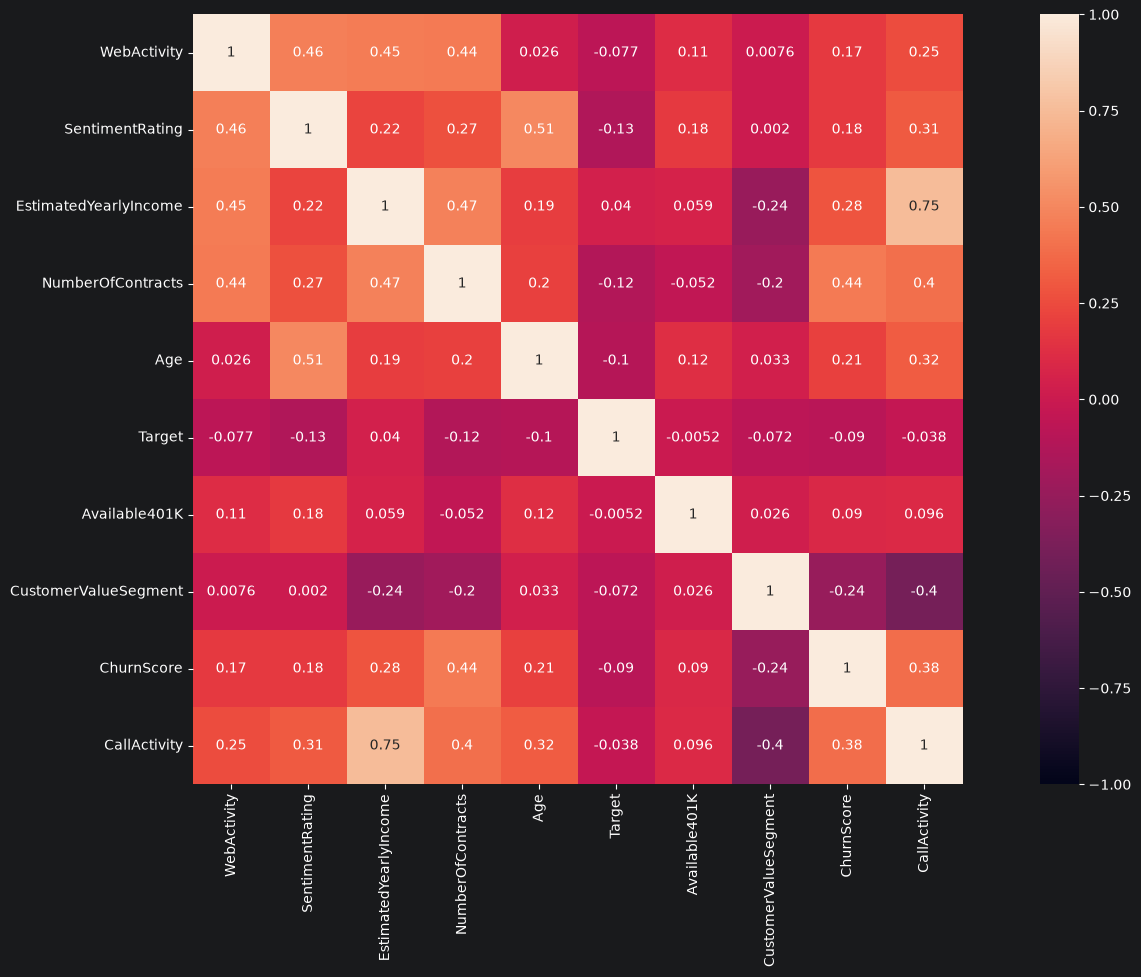

In [40]:
corr_matrix = sent_analysis_no_duplicates_and_keys.corr(numeric_only=True)
f, ax = plt.subplots(figsize=(20, 10))
sns.heatmap(corr_matrix,vmin=-1, vmax=1, square=True, annot=True)

In [42]:
sent_analysis_t1 = sent_analysis_no_duplicates_and_keys

## T2
Create plots to visualize the data.

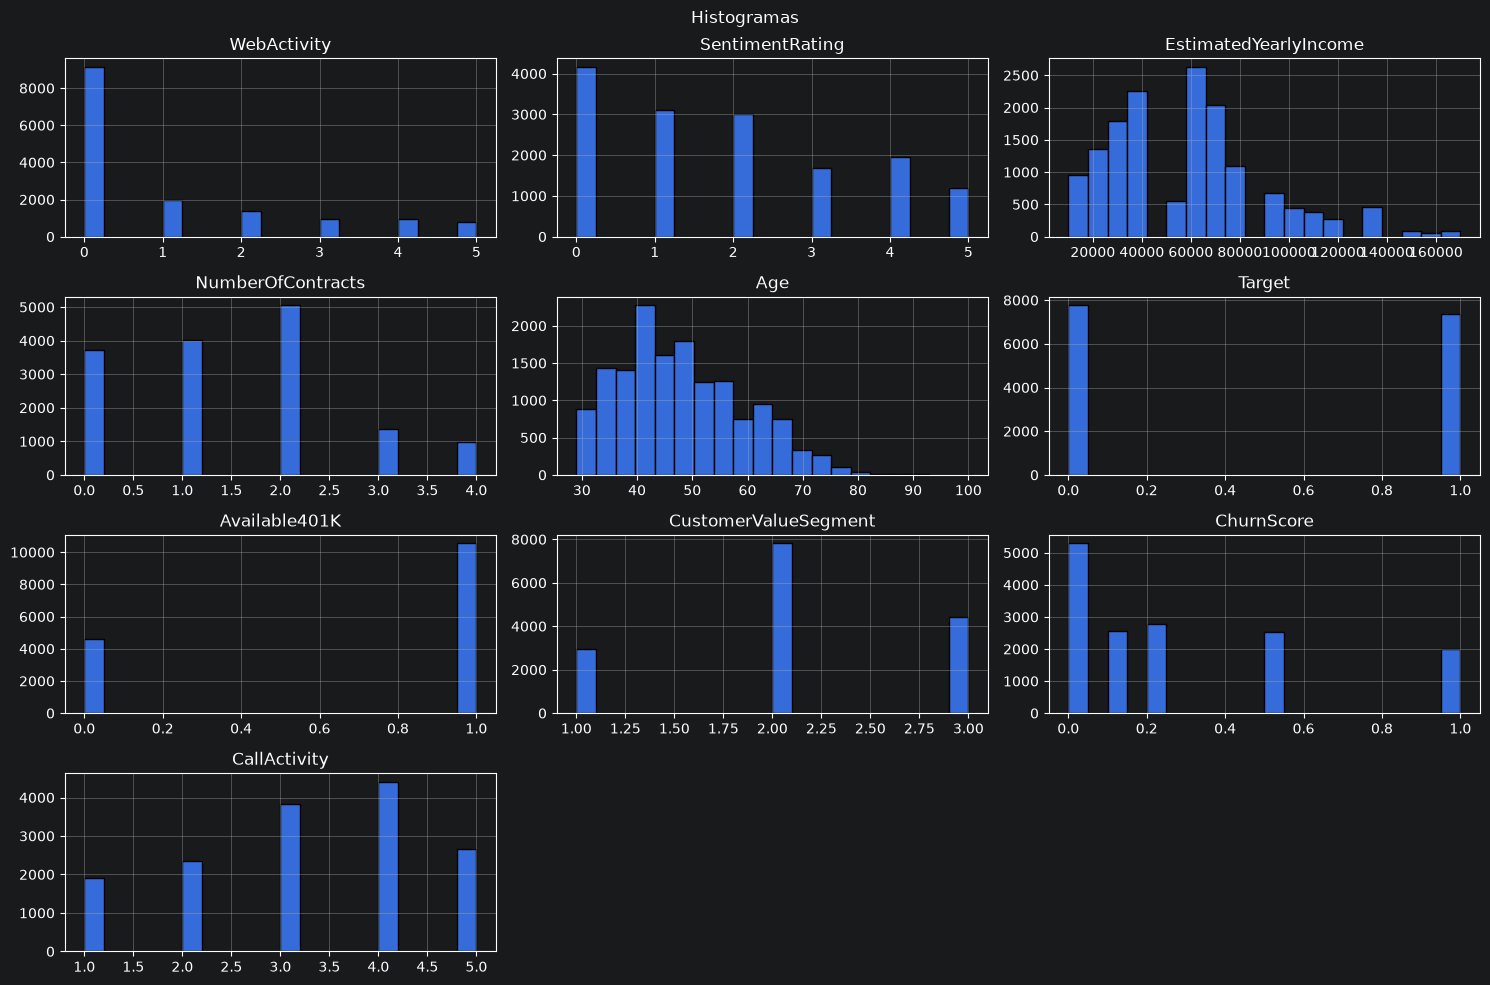

In [46]:
sent_analysis_t1[num_cols].hist(figsize=(15, 10), bins=20, edgecolor="black")
plt.suptitle("Histogramas");
plt.tight_layout();
plt.show()

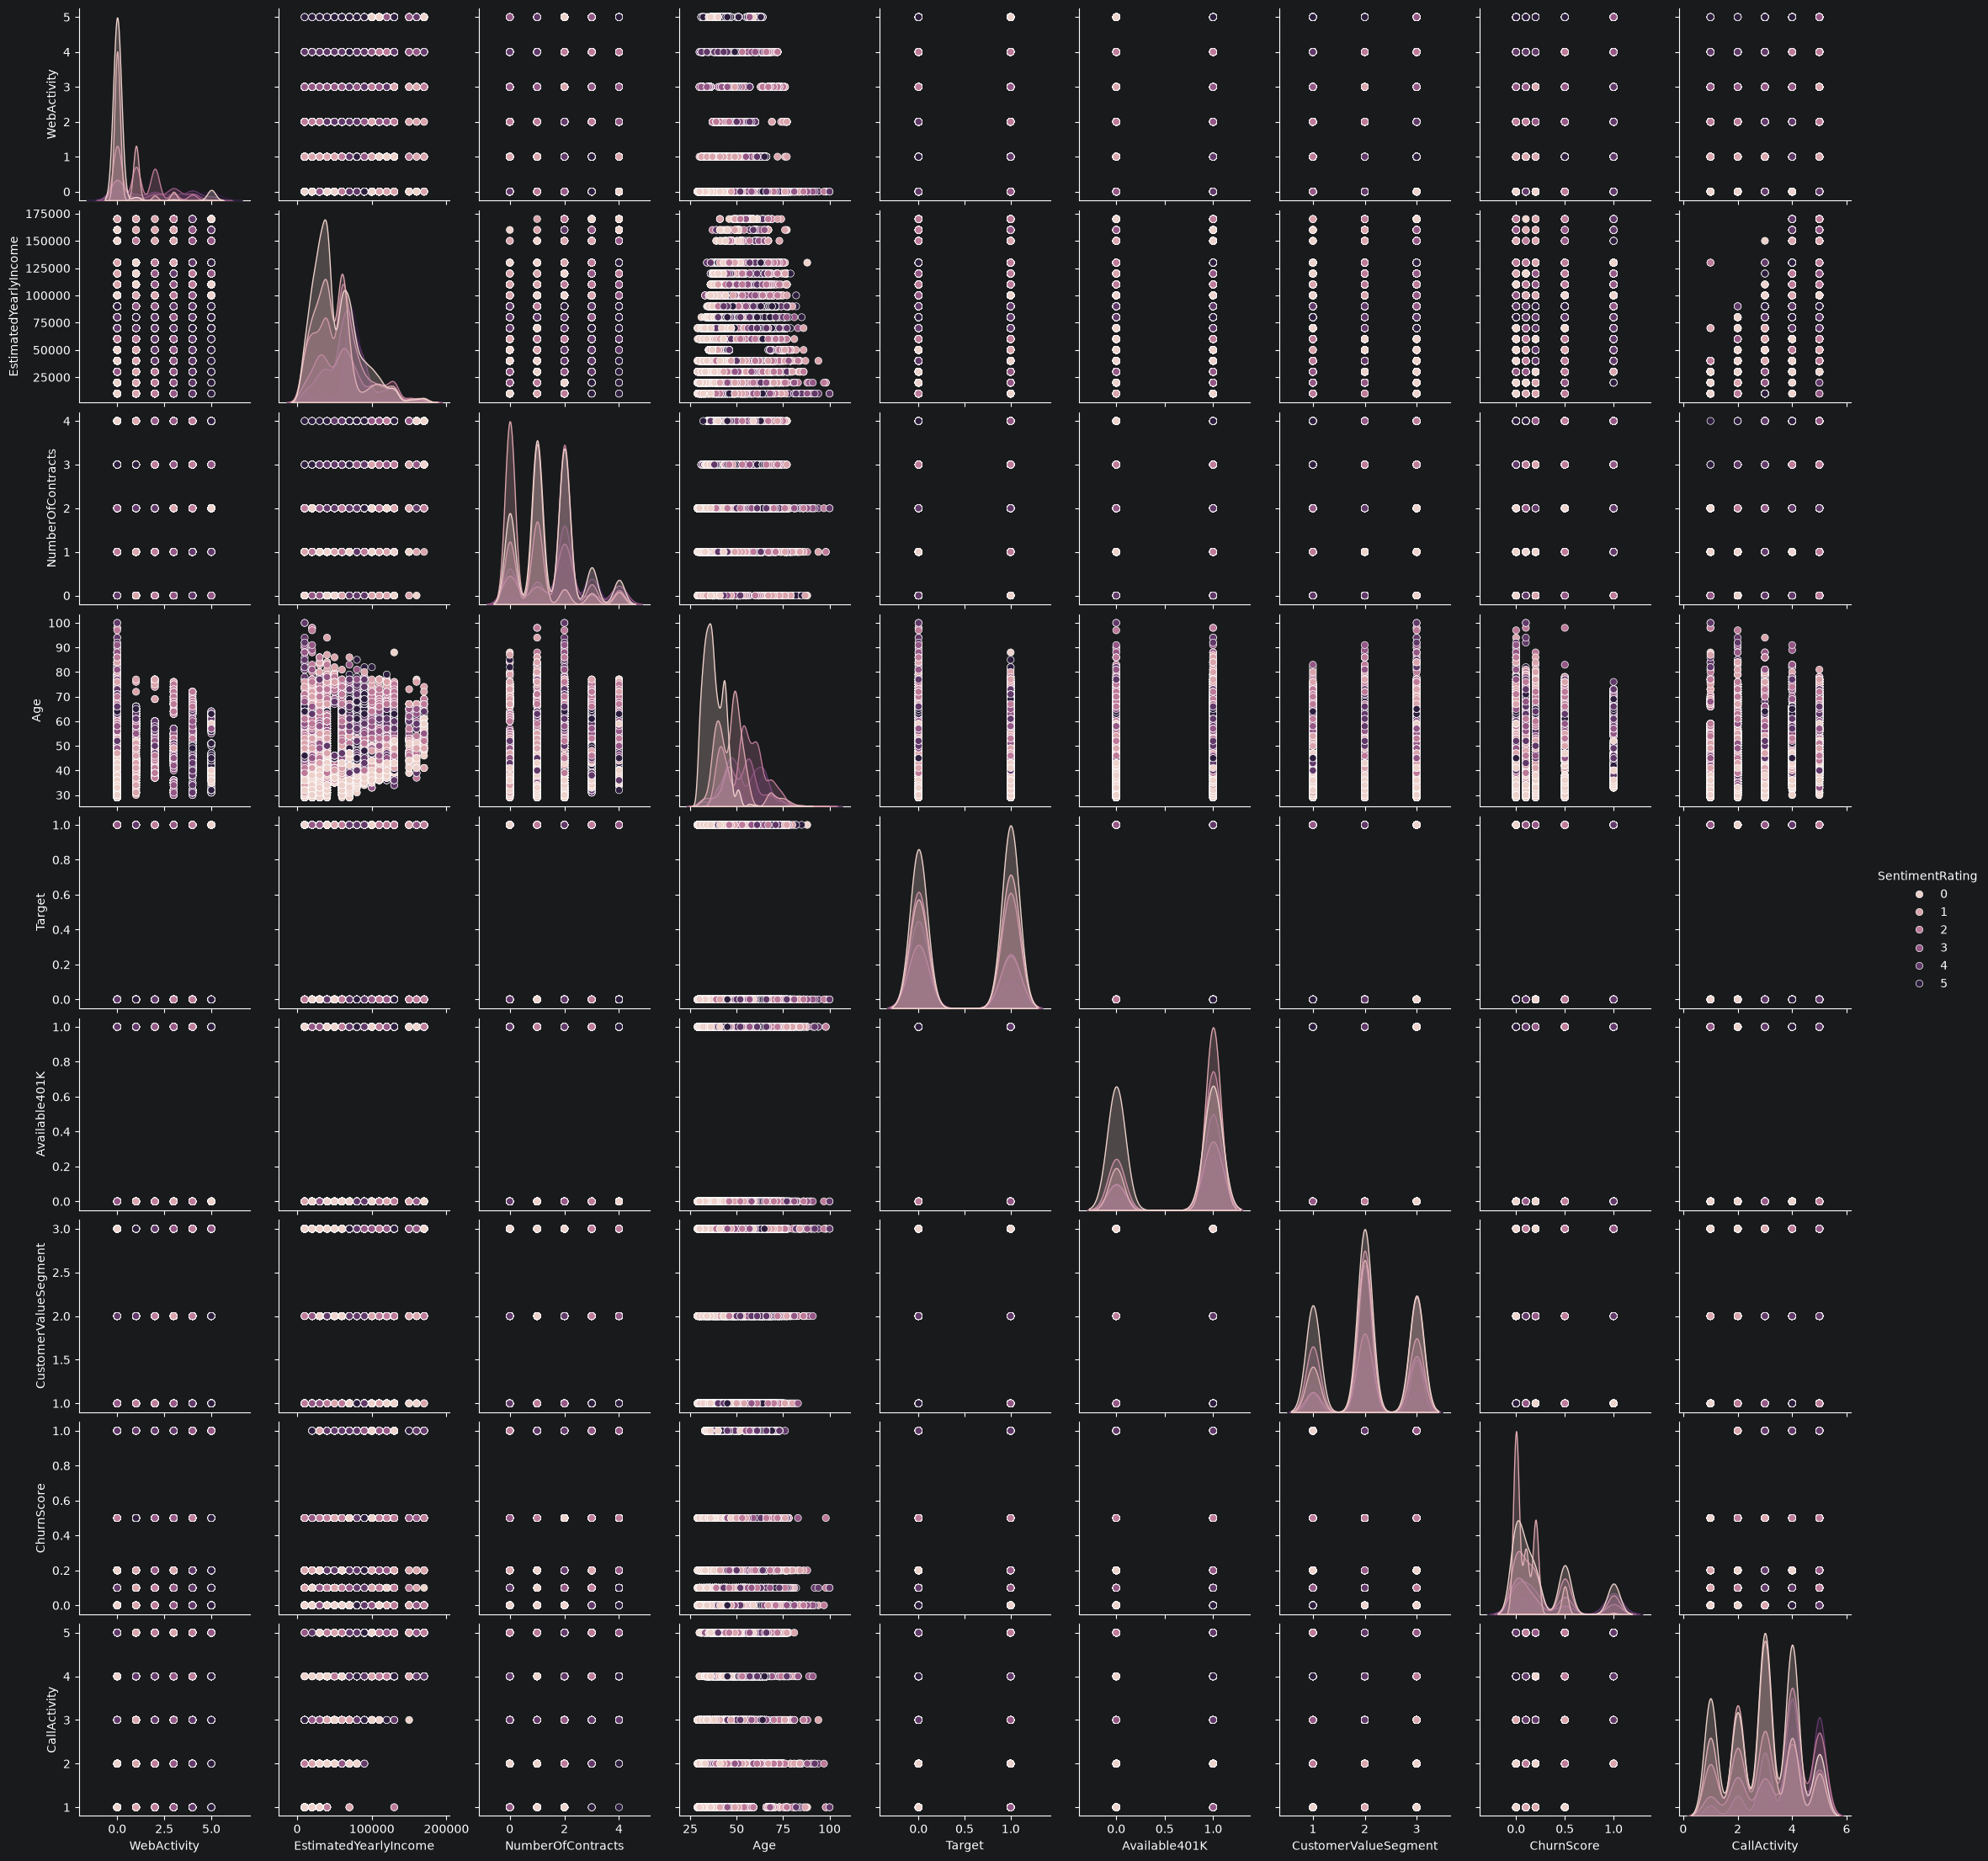

In [48]:
sns.pairplot(sent_analysis_t1, hue="SentimentRating")

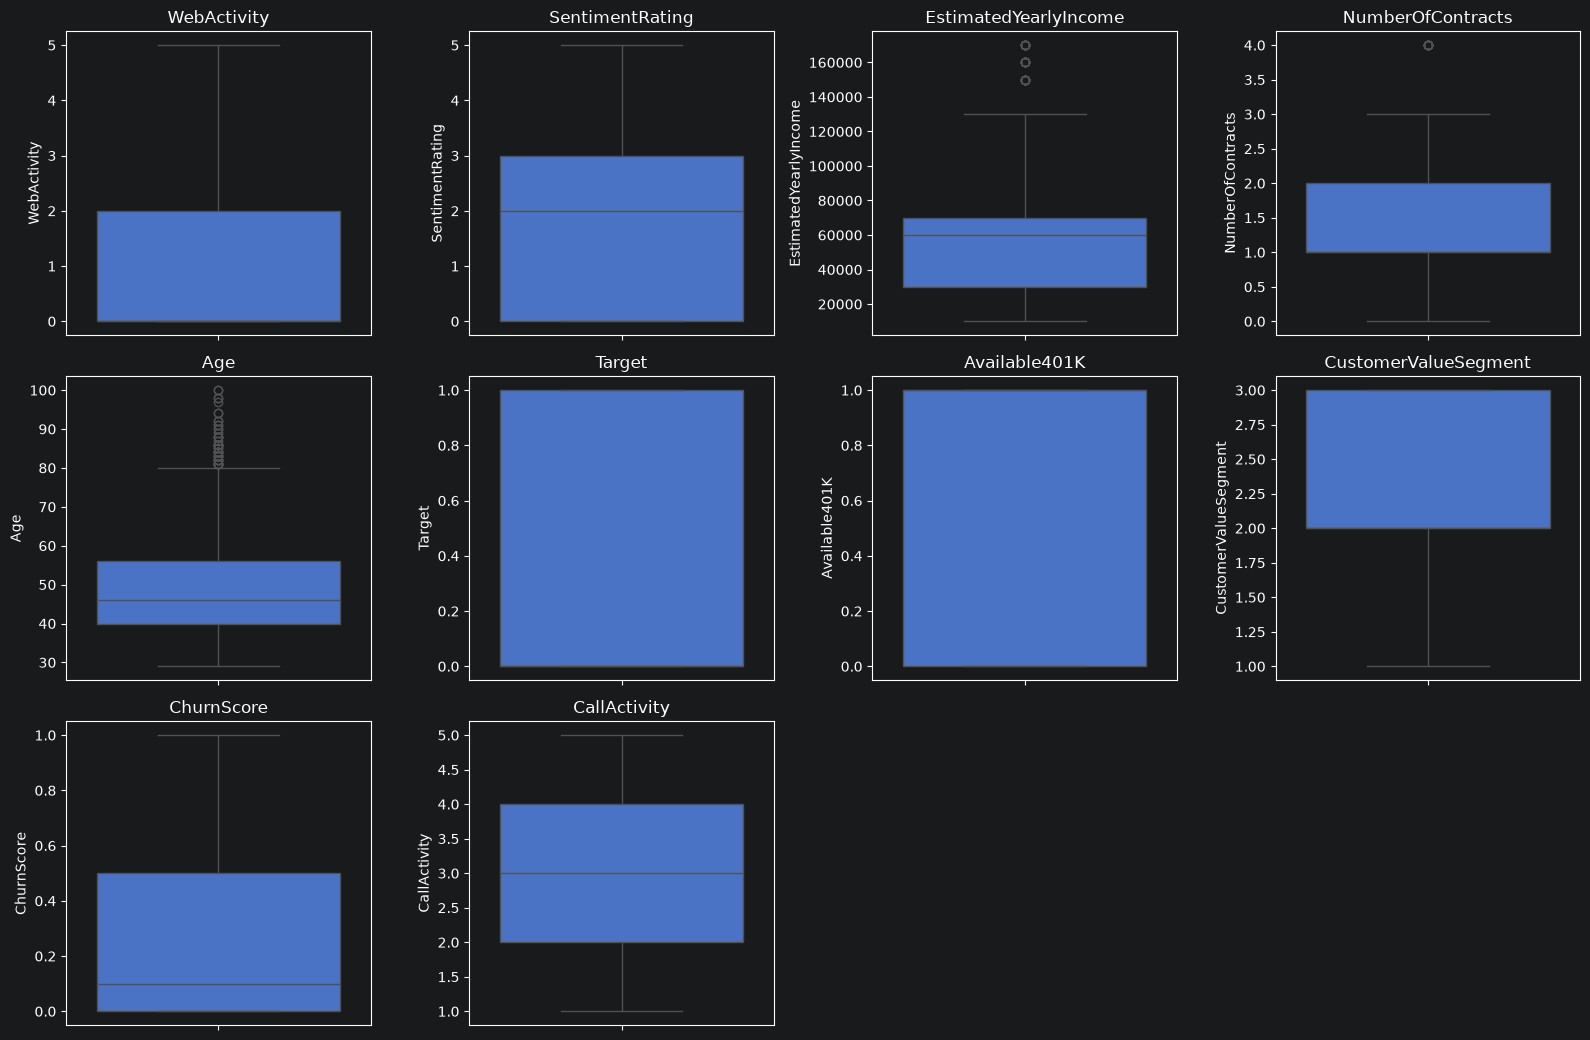

In [50]:
# Boxplots (outliers)
n = len(num_cols); cols = 4; rows = int(np.ceil(n / cols))
fig, axs = plt.subplots(rows, cols, figsize=(16, 3.5 * rows))
for ax, c in zip(axs.ravel(), num_cols):
    sns.boxplot(y=sent_analysis_t1[c], ax=ax); ax.set_title(c)
for ax in axs.ravel()[n:]:
    ax.axis("off")
plt.tight_layout(); plt.show()

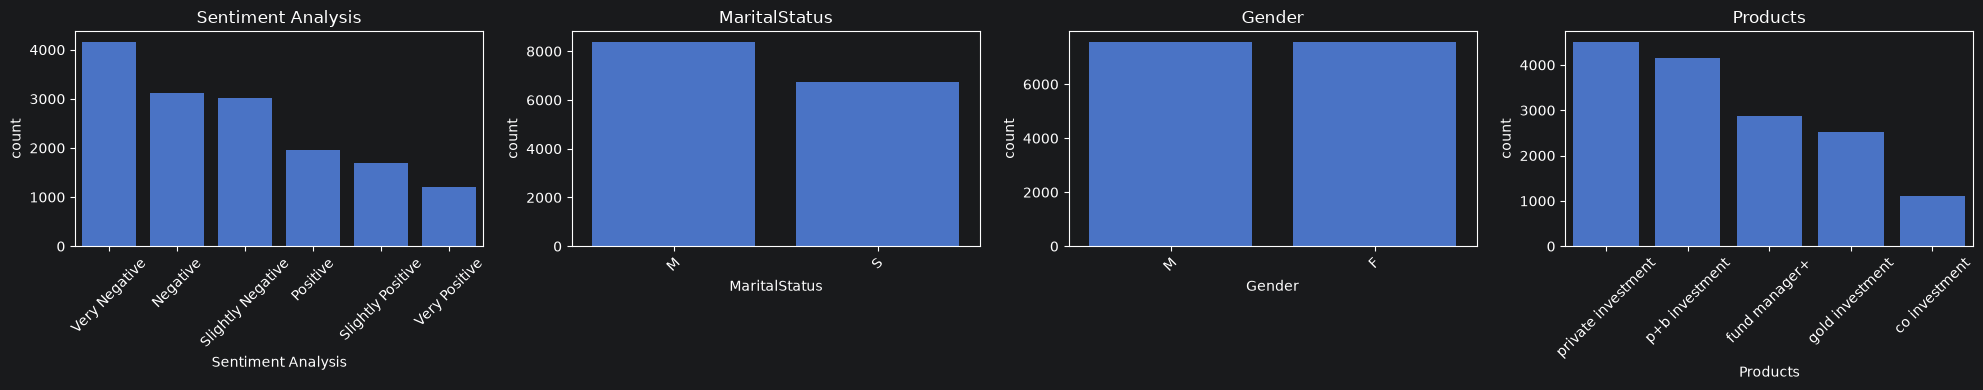

In [52]:
# Variáveis categóricas
small_cats = [c for c in cat_cols if sent_analysis_t1[c].nunique() <= 12]
fig, axs = plt.subplots(1, len(small_cats), figsize=(5 * len(small_cats), 4))
axs = np.atleast_1d(axs)
for ax, c in zip(axs, small_cats):
    order = sent_analysis_t1[c].value_counts().index
    sns.countplot(x=sent_analysis_t1[c], order=order, ax=ax); ax.set_title(c)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

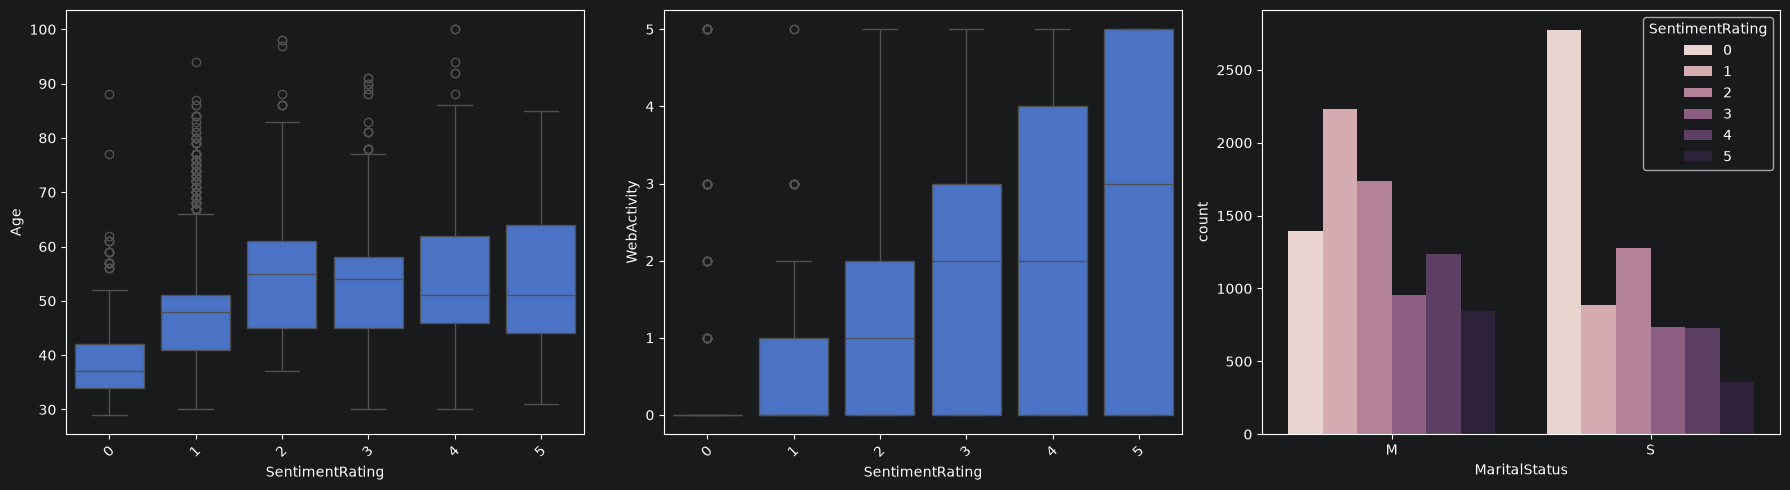

In [53]:
# Relações com o sentimento
fig, axs = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(x="SentimentRating", y="Age", data=sent_analysis_t1, ax=axs[0]); axs[0].tick_params(axis="x", rotation=45)
sns.boxplot(x="SentimentRating", y="WebActivity", data=sent_analysis_t1, ax=axs[1]); axs[1].tick_params(axis="x", rotation=45)
sns.countplot(x="MaritalStatus", hue="SentimentRating", data=sent_analysis_t1, ax=axs[2])
plt.tight_layout(); plt.show()

## T3
Apply different data treatments, such as:
-  Treating missing values;
-  Removing duplicate records;
-  Create an “age_binned” attribute by creating three bins of equal frequency on the “age” feature;
-  For each record, extract the year, month and day of the week from the “birthday” feature;
-  Remove users from the platform who have an activity on the platform ( “WebActivity”) of less than 1 hour and who are over 70 years old;
-  Use “Sentiment Analysis” to determine the mode of the remaining attributes;
-  Using “Sentiment Analysis” and “MaritalStatus”, obtain the average of the remaining attributes.

In [55]:
df_t = sent_analysis_t1.copy()
print("Missing (%):\n", (df_t.isna().mean() * 100).round(2))

Missing (%):
 WebActivity              0.0
Sentiment Analysis       0.0
SentimentRating          0.0
MaritalStatus            0.0
Gender                   0.0
EstimatedYearlyIncome    0.0
NumberOfContracts        0.0
Age                      0.0
Target                   0.0
Available401K            0.0
CustomerValueSegment     0.0
ChurnScore               0.0
CallActivity             0.0
Products                 0.0
birthday                 0.0
dtype: float64


In [56]:
for c in df_t.columns:
    if df_t[c].isna().any():
        if pd.api.types.is_numeric_dtype(df_t[c]):
            df_t[c] = df_t[c].fillna(df_t[c].median())
        else:
            df_t[c] = df_t[c].fillna(df_t[c].mode().iloc[0])
print("\nMissing depois:", df_t.isna().sum().sum())


Missing depois: 0


In [57]:
print("Duplicados exatos:", df_t.duplicated().sum())
df_t = df_t.drop_duplicates().reset_index(drop=True)
print("Shape:", df_t.shape)

Duplicados exatos: 29
Shape: (15122, 15)


In [58]:
est = preprocessing.KBinsDiscretizer(n_bins=3, encode="ordinal", strategy="quantile")
df_t["age_binned"] = est.fit_transform(df_t[["Age"]]).astype(int)
print("Limites dos bins:", est.bin_edges_[0])
print(df_t["age_binned"].value_counts().sort_index())

Limites dos bins: [ 29.  42.  52. 100.]
age_binned
0    4887
1    4929
2    5306
Name: count, dtype: int64


In [59]:
df_t["birthday"] = pd.to_datetime(df_t["birthday"], errors="coerce")
print("Datas inválidas:", df_t["birthday"].isna().sum())
df_t["birth_year"] = df_t["birthday"].dt.year
df_t["birth_month"] = df_t["birthday"].dt.month
df_t["birth_weekday"] = df_t["birthday"].dt.day_name()   # ou .dt.dayofweek (0=segunda)
df_t[["birthday", "birth_year", "birth_month", "birth_weekday"]].head()

Datas inválidas: 0


,birthday,birth_year,birth_month,birth_weekday
0,1972-01-14,1972,1,Friday
1,1971-08-28,1971,8,Saturday
2,1970-06-26,1970,6,Friday
3,1971-02-11,1971,2,Thursday
4,1971-01-27,1971,1,Wednesday


In [61]:
mask = (df_t["WebActivity"] < 1) & (df_t["Age"] > 70)
print("Registos a remover:", mask.sum())

df_t = df_t[~mask].reset_index(drop=True)
print("Shape final:", df_t.shape)

Registos a remover: 457
Shape final: (14665, 19)


In [63]:
mode_by_sent = df_t.drop(columns=["birthday"]).groupby("Sentiment Analysis").agg(lambda s: s.mode().iloc[0])
mode_by_sent

,WebActivity,SentimentRating,MaritalStatus,Gender,EstimatedYearlyIncome,NumberOfContracts,Age,Target,Available401K,CustomerValueSegment,ChurnScore,CallActivity,Products,age_binned,birth_year,birth_month,birth_weekday
Sentiment Analysis,,,,,,,,,,,,,,,,,
Negative,0,1,M,F,60000,0,48,1,1,2,0.0,3,private investment,1,1967,7,Wednesday
Positive,0,4,M,M,70000,2,46,0,1,2,1.0,4,private investment,2,1969,1,Thursday
Slightly Negative,0,2,M,M,60000,2,53,1,1,2,0.0,4,p+b investment,2,1962,12,Monday
Slightly Positive,0,3,M,F,30000,2,45,0,1,2,0.0,4,p+b investment,2,1959,6,Friday
Very Negative,0,0,S,M,40000,1,36,1,1,2,0.0,3,p+b investment,0,1979,4,Friday
Very Positive,0,5,M,F,70000,2,65,0,1,2,1.0,4,private investment,2,1951,10,Friday


In [64]:
mean_by = df_t.groupby(["Sentiment Analysis", "MaritalStatus"]).mean(numeric_only=True)
mean_by

WebActivity  SentimentRating  \
Sentiment Analysis MaritalStatus                                 
Negative           M                 0.412039              1.0   
                   S                 0.490128              1.0   
Positive           M                 1.863676              4.0   
                   S                 2.038136              4.0   
Slightly Negative  M                 1.124549              2.0   
                   S                 1.148726              2.0   
Slightly Positive  M                 1.682022              3.0   
                   S                 1.815864              3.0   
Very Negative      M                 0.605187              0.0   
                   S                 0.145441              0.0   
Very Positive      M                 2.652761              5.0   
                   S                 2.193182              5.0   

                                  EstimatedYearlyIncome  NumberOfContracts  \
Sentiment Analysis MaritalStatus                                             
Negative           M                       51474.568362           0.717685   
                   S                       53321.718931           0.751452   
Positive           M                       71328.731665           1.711821   
                   S                       66214.689266           1.793785   
Slightly Negative  M                       61516.245487           1.645608   
                   S                       53623.664749           1.342646   
Slightly Positive  M                       69202.247191           1.884270   
                   S                       54235.127479           1.662890   
Very Negative      M                       55720.461095           1.481268   
                   S                       49446.454414           1.431621   
Very Positive      M                       74208.588957           2.456442   
                   S                       65852.272727           2.340909   

                                        Age    Target  Available401K  \
Sentiment Analysis MaritalStatus                                       
Negative           M              47.041531  0.535698       0.886141   
                   S              46.255517  0.643438       0.629501   
Positive           M              53.667817  0.347714       0.795513   
                   S              51.656780  0.440678       0.771186   
Slightly Negative  M              55.884477  0.447653       0.753309   
                   S              50.507806  0.599836       0.708299   
Slightly Positive  M              52.939326  0.455056       0.731461   
                   S              49.609065  0.502833       0.713881   
Very Negative      M              37.742795  0.546110       0.677233   
                   S              37.566570  0.528582       0.412808   
Very Positive      M              53.363190  0.256442       0.800000   
                   S              53.840909  0.485795       0.775568   

                                  CustomerValueSegment  ChurnScore  \
Sentiment Analysis MaritalStatus                                     
Negative           M                          2.234251    0.104433   
                   S                          2.133566    0.128107   
Positive           M                          2.134599    0.374116   
                   S                          2.166667    0.383333   
Slightly Negative  M                          1.965102    0.297112   
                   S                          2.146261    0.238209   
Slightly Positive  M                          2.216854    0.310674   
                   S                          2.281870    0.197167   
Very Negative      M                          1.958213    0.330980   
                   S                          2.057887    0.257091   
Very Positive      M                          1.877301    0.452638   
                   S                          2.036932    0.450000   

                          

Ideias para o T4

A empresa tem um problema com clientes jovens, solteiros e pouco ativos na plataforma, que são os mais insatisfeitos. Faz sentido criar campanhas dirigidas a esse segmento e incentivar o uso da plataforma.
SentimentRating é só uma codificação numérica de Sentiment Analysis, por isso não deve entrar como variável independente.
Relaciona a alínea e) com o exemplo de Abraham Wald das slides, porque remover os mais velhos e inativos pode enviesar a análise.
Refere que correlação não implica causalidade.

## II
EPL Players Stats Dataset Download the dataset, which is available at https://bit.ly/3525yDr, to access data on the performance of various football players in the 2017/2018 Premier League season.

Complete the following tasks:

## T5.
Load the dataset. Explore the data and look for relevant information to display.

In [65]:
epl = pd.read_csv("datasets3/EPL_Player_Stats_2017_2018.csv")
print(epl.shape)
epl.info()

(515, 26)
<class 'pandas.DataFrame'>
RangeIndex: 515 entries, 0 to 514
Data columns (total 26 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        515 non-null    int64  
 1   pens_made                 515 non-null    int64  
 2   goals_assists_per90       515 non-null    float64
 3   position                  515 non-null    str    
 4   fouls                     515 non-null    int64  
 5   goals                     515 non-null    int64  
 6   player                    515 non-null    str    
 7   goals_assists_pens_per90  515 non-null    float64
 8   squad                     515 non-null    str    
 9   goals_per90               515 non-null    float64
 10  minutes_per_game          515 non-null    int64  
 11  games_starts              515 non-null    int64  
 12  games_subs                515 non-null    int64  
 13  cards_per90               515 non-null    float64
 14  shots_on_ta

In [66]:
epl.head()

,id,pens_made,goals_assists_per90,position,fouls,goals,player,goals_assists_pens_per90,squad,goals_per90,...,games,cards_yellow,cards_red,nationality,assists,minutes,fouls_per90,age,shots_on_target,pens_att
0,0,0,0.05,DF,44,0,Mathias Jørgensen,0.05,Huddersfield Town,0.00,...,38,6,0,dk DEN,2,"3,420",1.16,27,3,0
1,1,0,0.05,DF,36,1,Lewis Dunk,0.05,Brighton & Hove Albion,0.03,...,38,7,0,eng ENG,1,"3,420",0.95,25,9,0
2,2,0,0.00,GK,0,0,Mathew Ryan,0.00,Brighton & Hove Albion,0.00,...,38,0,0,au AUS,0,"3,420",0.00,25,0,0
3,3,0,0.00,GK,1,0,Jordan Pickford,0.00,Everton,0.00,...,38,0,0,eng ENG,0,"3,420",0.03,23,0,0
4,4,0,0.08,"DF,MF",23,2,Jack Cork,0.08,Burnley,0.05,...,38,7,0,eng ENG,1,"3,420",0.61,28,5,0


In [76]:
# 'minutes' vem como texto com vírgula ("3,420") -> converter para número
epl["minutes"] = epl["minutes"].astype(str).str.replace(",", "").astype(int)

# 'nationality' vem como "eng ENG" / "dk DEN": ficar com o código de 3 letras (maiúsculas)
epl["nationality"] = epl["nationality"].str.split().str[-1]

print("Missing:\n", epl.isna().sum()[epl.isna().sum() > 0])
print("Duplicados:", epl.duplicated().sum())
epl[epl["nationality"].isna()]

Missing:
 nationality    1
dtype: int64
Duplicados: 0


,id,pens_made,goals_assists_per90,position,fouls,goals,player,goals_assists_pens_per90,squad,goals_per90,...,games,cards_yellow,cards_red,nationality,assists,minutes,fouls_per90,age,shots_on_target,pens_att
488,488,0,0.0,MF,0,0,Callum Hudson-Odoi,0.0,Chelsea,0.0,...,2,0,0,NaN,0,29,0.0,16,1,0


In [77]:
epl.describe().T

,count,mean,std,min,25%,50%,75%,max
id,515.0,257.000000,148.811962,0.0,128.500,257.00,385.50,514.00
pens_made,515.0,0.106796,0.556403,0.0,0.000,0.00,0.00,7.00
goals_assists_per90,515.0,0.188777,0.313034,0.0,0.000,0.09,0.28,4.50
fouls,515.0,15.112621,13.958350,0.0,3.000,13.00,23.50,69.00
goals,515.0,1.887379,3.578869,0.0,0.000,0.00,2.00,32.00
goals_assists_pens_per90,515.0,0.184350,0.308403,0.0,0.000,0.09,0.26,4.50
goals_per90,515.0,0.103709,0.173157,0.0,0.000,0.00,0.15,1.08
minutes_per_game,515.0,64.768932,23.650318,1.0,51.000,73.00,84.00,90.00
games_starts,515.0,16.066019,11.795580,0.0,4.500,16.00,25.00,38.00
games_subs,515.0,3.937864,4.516725,0.0,1.000,2.00,5.00,23.00


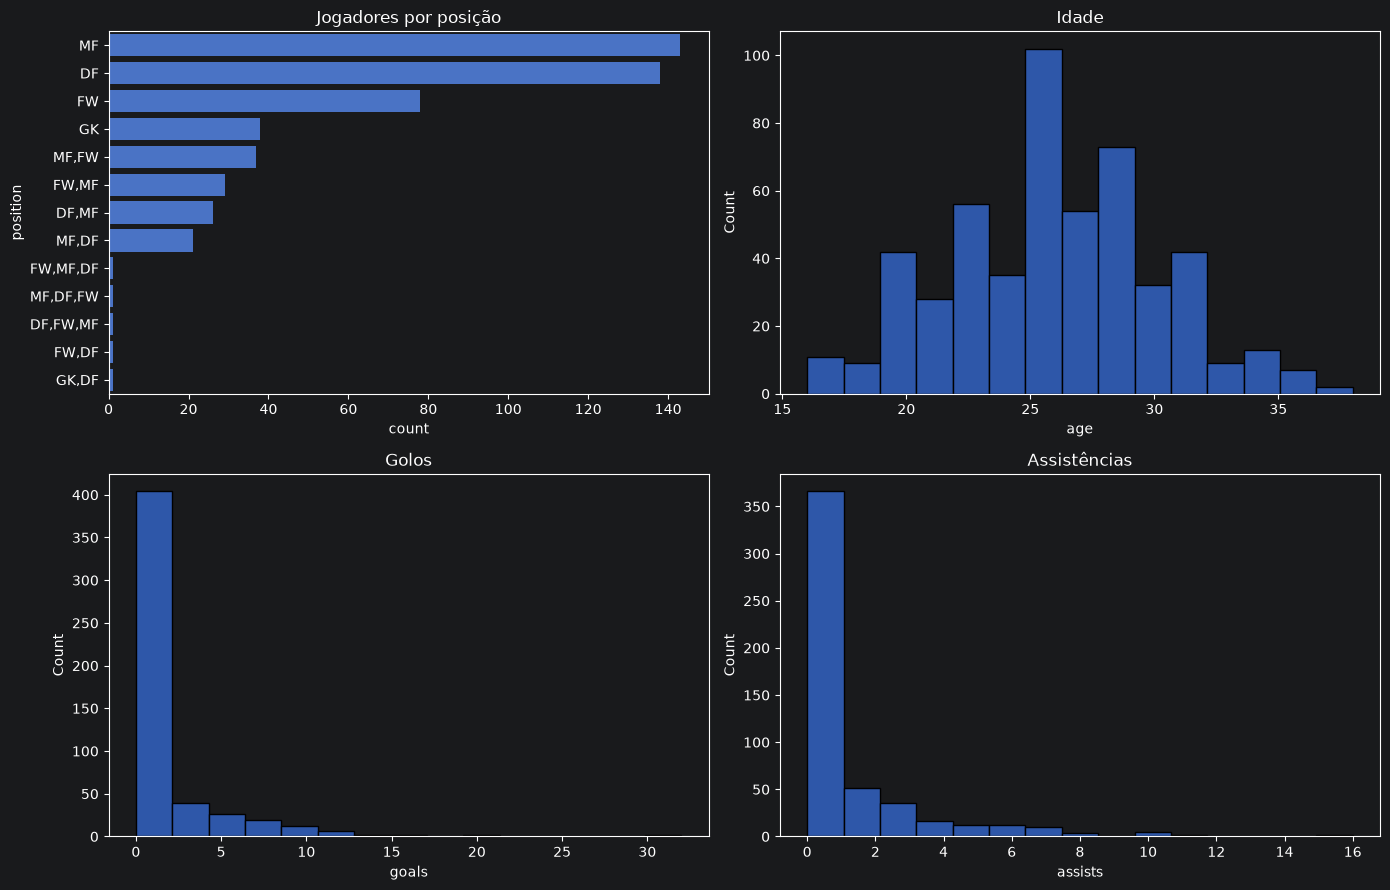

In [78]:
# Visualizações gerais
fig, axs = plt.subplots(2, 2, figsize=(14, 9))
sns.countplot(y=epl["position"], order=epl["position"].value_counts().index, ax=axs[0, 0]); axs[0, 0].set_title("Jogadores por posição")
sns.histplot(epl["age"], bins=15, ax=axs[0, 1]); axs[0, 1].set_title("Idade")
sns.histplot(epl["goals"], bins=15, ax=axs[1, 0]); axs[1, 0].set_title("Golos")
sns.histplot(epl["assists"], bins=15, ax=axs[1, 1]); axs[1, 1].set_title("Assistências")
plt.tight_layout(); plt.show()

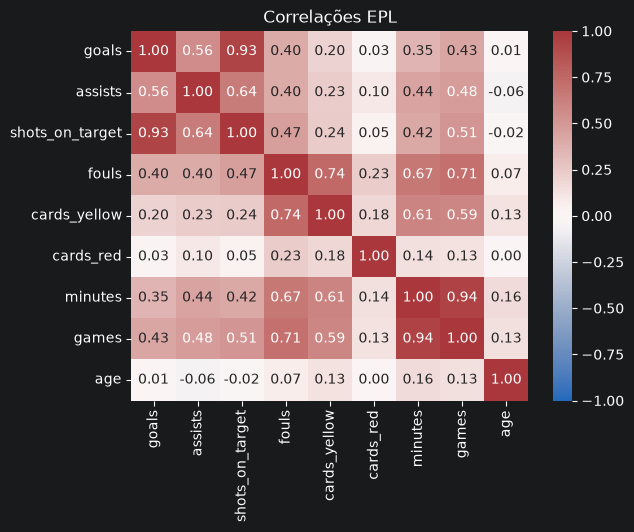

In [79]:
cols = ["goals", "assists", "shots_on_target", "fouls", "cards_yellow", "cards_red", "minutes", "games", "age"]
sns.heatmap(epl[cols].corr(), annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1)
plt.title("Correlações EPL"); plt.show()

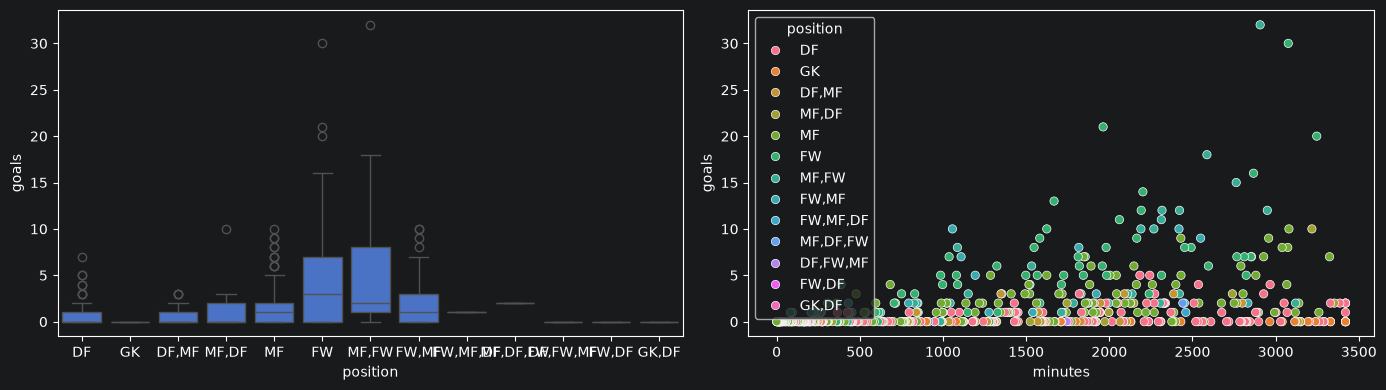

In [80]:
# Golos por posição e idade vs golos
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(x="position", y="goals", data=epl, ax=axs[0])
sns.scatterplot(x="minutes", y="goals", hue="position", data=epl, ax=axs[1])
plt.tight_layout(); plt.show()

## T6.
Critically analyze the dataset. For example, which team is the most undisciplined? What are the top 10 assists for goals? Which nationalities feature most prominently (top 5) in this edition of the Premier League?

In [81]:
### Qual é a equipa mais indisciplinada?
disc = epl.groupby("squad").agg(amarelos=("cards_yellow", "sum"),
                                vermelhos=("cards_red", "sum"),
                                faltas=("fouls", "sum"))
disc["cartoes"] = disc["amarelos"] + disc["vermelhos"]
disc["pontos_disciplina"] = disc["amarelos"] + 3 * disc["vermelhos"]   # vermelho pesa mais (escolha nossa)
disc = disc.sort_values("pontos_disciplina", ascending=False)
print("Mais indisciplinada (amarelos + 3*vermelhos):", disc.index[0])
print("Mais cartões no total:", disc["cartoes"].idxmax(), "| Mais faltas:", disc["faltas"].idxmax())
disc

Mais indisciplinada (amarelos + 3*vermelhos): West Ham United
Mais cartões no total: West Ham United | Mais faltas: Everton


,amarelos,vermelhos,faltas,cartoes,pontos_disciplina
squad,,,,,
West Ham United,72,2,371,74,78
Watford,64,4,440,68,76
West Bromwich Albion,73,1,440,74,76
Crystal Palace,72,0,425,72,72
Huddersfield Town,63,3,397,66,72
Southampton,64,2,415,66,70
Leicester City,55,5,357,60,70
Manchester City,61,2,343,63,67
Stoke City,62,1,433,63,65


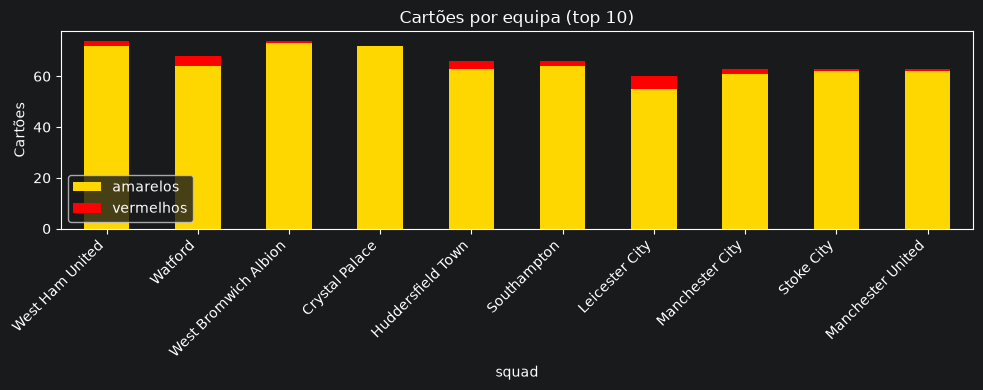

In [82]:
disc.head(10)[["amarelos", "vermelhos"]].plot(kind="bar", stacked=True, color=["gold", "red"], figsize=(10, 4))
plt.title("Cartões por equipa (top 10)"); plt.ylabel("Cartões"); plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

In [83]:
### Top 10 assistências

# %%
top_assists = epl.sort_values(["assists", "goals"], ascending=False).head(10)[["player", "squad", "assists"]]
top_assists

,player,squad,assists
37,Kevin De Bruyne,Manchester City,16
104,Leroy Sané,Manchester City,15
85,Raheem Sterling,Manchester City,11
101,David Silva,Manchester City,11
52,Mohamed Salah,Liverpool,10
49,Riyad Mahrez,Leicester City,10
23,Christian Eriksen,Tottenham Hotspur,10
48,Dele Alli,Tottenham Hotspur,10
142,Paul Pogba,Manchester United,10
51,Pascal Groß,Brighton & Hove Albion,8


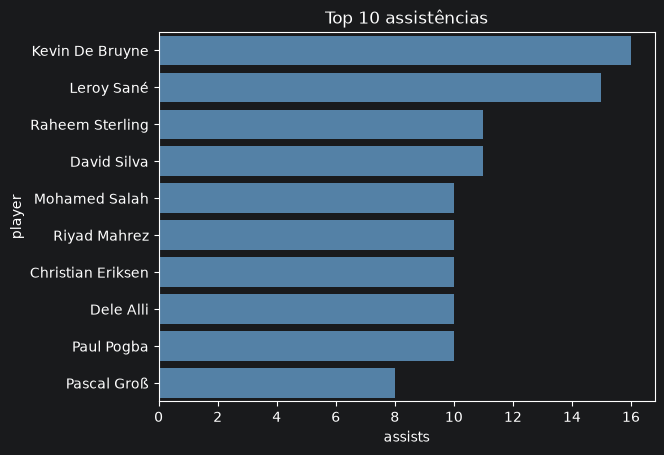

In [84]:
sns.barplot(y="player", x="assists", data=top_assists, color="steelblue")
plt.title("Top 10 assistências"); plt.show()

nationality
ENG    174
ESP     32
FRA     29
NED     23
BEL     21
Name: count, dtype: int64


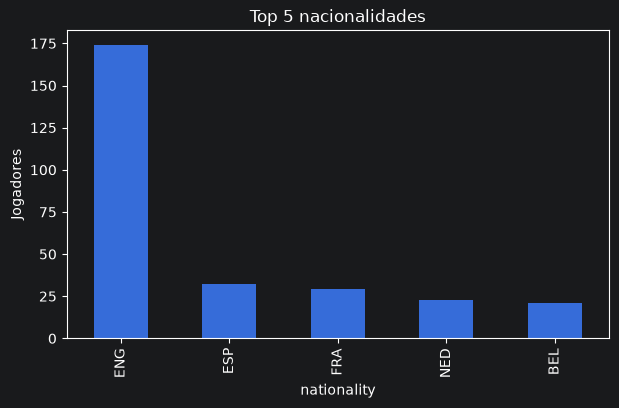

In [85]:
### Top 5 nacionalidades

# %%
top_nat = epl["nationality"].value_counts().head(5)
print(top_nat)
top_nat.plot(kind="bar", figsize=(7, 4)); plt.title("Top 5 nacionalidades"); plt.ylabel("Jogadores"); plt.show()

                  player              squad  goals
52         Mohamed Salah          Liverpool     32
36            Harry Kane  Tottenham Hotspur     30
171        Sergio Agüero    Manchester City     21
20           Jamie Vardy     Leicester City     20
85       Raheem Sterling    Manchester City     18
58         Romelu Lukaku  Manchester United     16
76       Roberto Firmino          Liverpool     15
135  Alexandre Lacazette            Arsenal     14
225        Gabriel Jesus    Manchester City     13
102          Eden Hazard            Chelsea     12


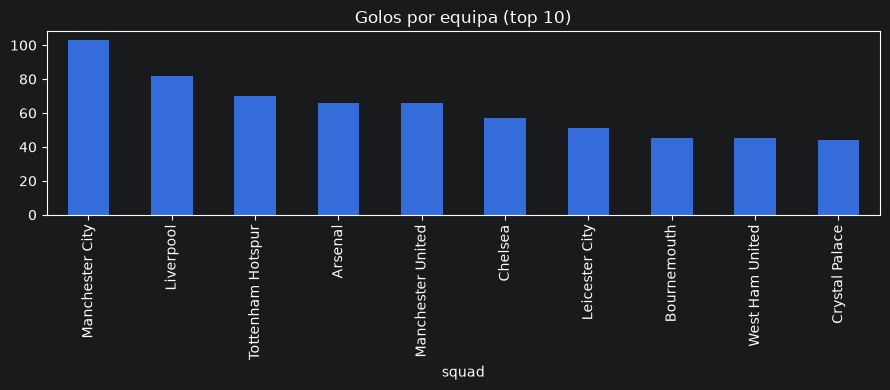

In [86]:
# Extras: top marcadores e golos por equipa
print(epl.sort_values("goals", ascending=False).head(10)[["player", "squad", "goals"]])
epl.groupby("squad")["goals"].sum().sort_values(ascending=False).head(10).plot(kind="bar", figsize=(9, 4))
plt.title("Golos por equipa (top 10)"); plt.tight_layout(); plt.show()